# 01 — Exploração inicial do dataset (Entrega 1 / M1)

**Objetivo:** produzir a evidência pedida na M1 — amostras, contagem de classes, dimensões, rótulos, metadados e uma hipótese de divisão treino/validação/teste — **sem treinar rede**.

**Dataset:** ISIC 2018 Challenge — Task 1 (segmentação, 2.594 imagens + máscaras) e Task 3 (classificação, 10.015 imagens = HAM10000, 7 classes) + metadados HAM10000 (idade, sexo, localização).

Convenção deste notebook: tudo o que aparece nas tabelas/figuras é **medido** nos arquivos em `data/raw/`. Interpretações ficam nas células de texto e são marcadas como *inferido*.

In [1]:
import os, sys, json, glob, random, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CFG = yaml.safe_load(open(ROOT / "configs/data.yaml"))
P = {k: ROOT / v for k, v in CFG.items() if isinstance(v, str) and k != "priority_class"}
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
SEED = CFG["seed"]; random.seed(SEED); np.random.seed(SEED)
CLASSES = CFG["classes"]
sns.set_theme(style="whitegrid"); plt.rcParams["figure.dpi"] = 110
EVID = {}  # resumo de evidências salvo ao final
print({k: (str(v), v.exists()) for k, v in P.items()})

{'raw_dir': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw', True), 'task1_images': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task1-2_Training_Input', True), 'task1_masks': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task1_Training_GroundTruth', True), 'task3_images': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task3_Training_Input', True), 'task3_labels': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task3_Training_GroundTruth/ISIC2018_Task3_Training_GroundTruth.csv', True), 'task3_groupings': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task3_Training_LesionGroupings.csv', True), 'task3_test_images': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av56/mnt/VISAO COMPUTACIONAL/data/raw/ISIC2018_Task3_Test_Input', True), 'task3_test_labels': ('/sessions/rcw-0136tm4hwui6zm3jtbu3av5

## 1. Inventário dos arquivos

Confere o que existe em disco, quantos arquivos por pasta e se cada imagem da Task 1 tem exatamente uma máscara.

In [2]:
def listar(d, ext):
    return sorted(Path(d).glob(f"*.{ext}")) if Path(d).exists() else []

t1_img = listar(P["task1_images"], "jpg")
t1_msk = listar(P["task1_masks"], "png")
t3_img = listar(P["task3_images"], "jpg")
t3_test = listar(P["task3_test_images"], "jpg")
print(f"Task1 imagens: {len(t1_img)} | máscaras: {len(t1_msk)}")
print(f"Task3 treino: {len(t3_img)} | Task3 teste oficial: {len(t3_test)}")
EVID["n_task3_test"] = len(t3_test)

ids_img = {p.stem for p in t1_img}
ids_msk = {p.stem.replace("_segmentation", "") for p in t1_msk}
print("Task1 imagens sem máscara:", len(ids_img - ids_msk), "| máscaras sem imagem:", len(ids_msk - ids_img))

# sobreposição de IDs entre as tarefas (importa para o split e para o experimento 'recorte pela máscara')
ids_t3 = {p.stem for p in t3_img}
inter = ids_img & ids_t3
print("IDs em comum Task1 ∩ Task3:", len(inter))
EVID.update(n_task1=len(t1_img), n_task1_masks=len(t1_msk), n_task3=len(t3_img), task1_task3_overlap=len(inter))

Task1 imagens: 2594 | máscaras: 2594
Task3 treino: 10015 | Task3 teste oficial: 1512
Task1 imagens sem máscara: 0 | máscaras sem imagem: 0
IDs em comum Task1 ∩ Task3: 0


## 2. Rótulos de classificação (Task 3) e metadados (HAM10000)

O ground truth da Task 3 é one-hot em 7 colunas. Os metadados (idade, sexo, localização, `lesion_id`, `dx_type`) vêm do arquivo do HAM10000 e são unidos por `image_id`.

`lesion_id` é crítico: uma mesma lesão pode ter mais de uma imagem — se caírem em splits diferentes há **vazamento**.

linhas: 10015 | sem lesion_id: 0
rótulo GT ≠ metadado: 0


,n,pct
dx,,
MEL,1113.000000,11.11
NV,6705.000000,66.95
BCC,514.000000,5.13
AKIEC,327.000000,3.27
BKL,1099.000000,10.97
DF,115.000000,1.15
VASC,142.000000,1.42
razão maior/menor,58.304348,NaN


,treino_%,teste_oficial_%
MEL,11.1,11.3
NV,66.9,60.1
BCC,5.1,6.2
AKIEC,3.3,2.8
BKL,11.0,14.4
DF,1.1,2.9
VASC,1.4,2.3


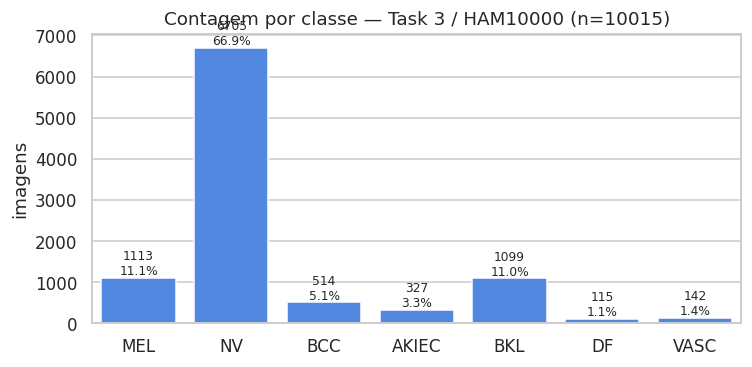

In [3]:
gt = pd.read_csv(P["task3_labels"])
gt.columns = [c.strip() for c in gt.columns]
gt["dx"] = gt[CLASSES].idxmax(axis=1)
assert (gt[CLASSES].sum(axis=1) == 1).all(), "rótulo não é one-hot"

# Agrupamento por lesão + tipo de confirmação (arquivo suplementar oficial do ISIC 2018)
grp = pd.read_csv(P["task3_groupings"]).rename(columns={"diagnosis_confirm_type": "dx_type"})
df = gt[["image", "dx"]].merge(grp, on="image", how="left")
print("linhas:", len(df), "| sem lesion_id:", df["lesion_id"].isna().sum())

# Metadados demográficos (HAM10000_metadata.csv) — opcional; sem ele a análise de subgrupo fica pendente
HAS_META = P["ham_metadata"].exists()
if HAS_META:
    meta = pd.read_csv(P["ham_metadata"])
    df = df.merge(meta[["image_id", "dx", "age", "sex", "localization"]].rename(columns={"dx": "dx_meta"}),
                  left_on="image", right_on="image_id", how="left").drop(columns="image_id")
    print("rótulo GT ≠ metadado:", (df["dx"] != df["dx_meta"].str.upper()).sum())
else:
    for c in ["age", "sex", "localization"]: df[c] = np.nan
    print("AVISO: HAM10000_metadata.csv ausente — idade/sexo/localização indisponíveis")
EVID["has_demographics"] = HAS_META

cnt = df["dx"].value_counts().reindex(CLASSES)
tab = pd.DataFrame({"n": cnt, "pct": (100 * cnt / cnt.sum()).round(2)})
tab.loc["razão maior/menor"] = [cnt.max() / cnt.min(), np.nan]
display(tab)
EVID["class_counts"] = cnt.to_dict(); EVID["imbalance_ratio"] = float(cnt.max() / cnt.min())

# Teste oficial do desafio (1.512 imagens) — distribuição de classes para comparar com o treino
if P["task3_test_labels"].exists():
    gtt = pd.read_csv(P["task3_test_labels"]); gtt.columns = [c.strip() for c in gtt.columns]
    cnt_t = gtt[CLASSES].idxmax(axis=1).value_counts().reindex(CLASSES)
    comp = pd.DataFrame({"treino_%": (100 * cnt / cnt.sum()).round(1), "teste_oficial_%": (100 * cnt_t / cnt_t.sum()).round(1)})
    display(comp); EVID["test_class_counts"] = cnt_t.to_dict()

fig, ax = plt.subplots(figsize=(7, 3.5))
sns.barplot(x=cnt.index, y=cnt.values, ax=ax, color="#3b82f6")
for i, v in enumerate(cnt.values): ax.text(i, v, f"{v}\n{100*v/cnt.sum():.1f}%", ha="center", va="bottom", fontsize=8)
ax.set(title="Contagem por classe — Task 3 / HAM10000 (n=%d)" % cnt.sum(), ylabel="imagens", xlabel="")
plt.tight_layout(); plt.savefig(FIG / "01_contagem_classes.png"); plt.show()

lesões únicas: 7470 | lesões com >1 imagem: 1956 | máx imagens/lesão: 6

faltantes por coluna:
age             57
sex              0
localization     0
dx_type          0
dtype: int64

sex:
sex
male       5406
female     4552
unknown      57
Name: count, dtype: int64

dx_type (como o rótulo foi obtido):
dx_type
histopathology                                   5340
serial imaging showing no change                 3704
single image expert consensus                     902
confocal microscopy with consensus dermoscopy      69
Name: count, dtype: int64


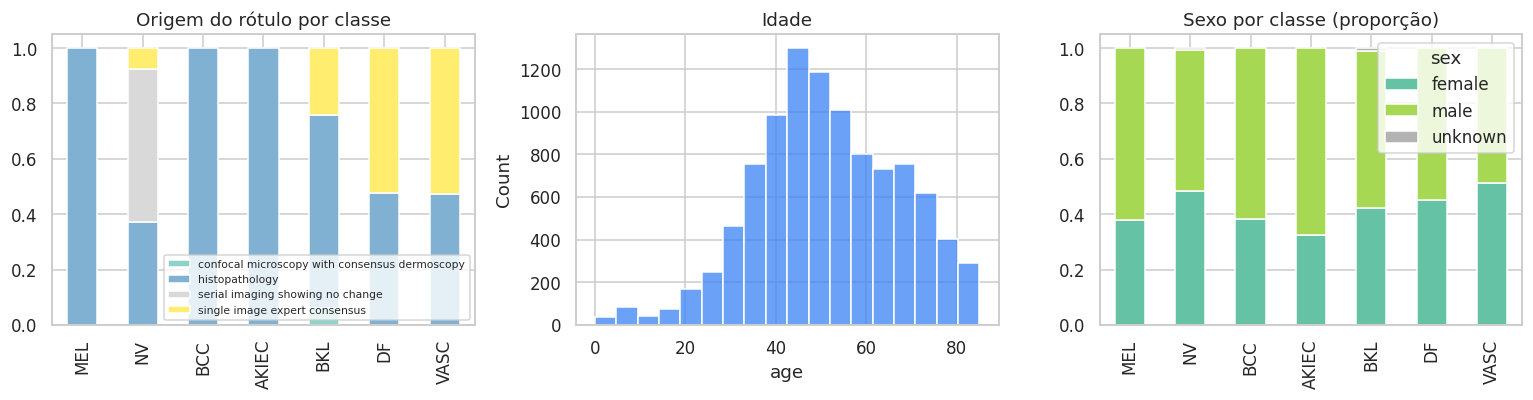

histopatologia por classe (%):
dx
MEL      100.0
NV        37.3
BCC      100.0
AKIEC    100.0
BKL       69.7
DF        47.8
VASC      47.2
Name: histopathology, dtype: float64


In [4]:
# Imagens por lesão (mesma lesão, várias fotos)
img_por_lesao = df.groupby("lesion_id")["image"].count()
print("lesões únicas:", img_por_lesao.size, "| lesões com >1 imagem:", (img_por_lesao > 1).sum(),
      "| máx imagens/lesão:", img_por_lesao.max())
EVID.update(n_lesions=int(img_por_lesao.size), lesions_multi_image=int((img_por_lesao > 1).sum()))

# Metadados: faltantes e distribuições
print("\nfaltantes por coluna:"); print(df[["age", "sex", "localization", "dx_type"]].isna().sum())
print("\nsex:"); print(df["sex"].value_counts(dropna=False))
print("\ndx_type (como o rótulo foi obtido):"); print(df["dx_type"].value_counts(dropna=False))
EVID["dx_type"] = df["dx_type"].value_counts(dropna=False).to_dict()

ncol = 3 if HAS_META else 1
fig, axes = plt.subplots(1, ncol, figsize=(4.7 * ncol, 3.8), squeeze=False); axes = axes[0]
ct2 = pd.crosstab(df["dx"], df["dx_type"], normalize="index").reindex(CLASSES)
ct2.plot(kind="bar", stacked=True, ax=axes[0], colormap="Set3"); axes[0].set_title("Origem do rótulo por classe"); axes[0].set_xlabel("")
axes[0].legend(fontsize=7, loc="lower right")
if HAS_META:
    sns.histplot(df["age"].dropna(), bins=18, ax=axes[1], color="#3b82f6"); axes[1].set_title("Idade")
    ct = pd.crosstab(df["dx"], df["sex"], normalize="index").reindex(CLASSES)
    ct.plot(kind="bar", stacked=True, ax=axes[2], colormap="Set2"); axes[2].set_title("Sexo por classe (proporção)"); axes[2].set_xlabel("")
plt.tight_layout(); plt.savefig(FIG / "02_metadados.png"); plt.show()
print("histopatologia por classe (%):"); print((ct2.get("histopathology", pd.Series(dtype=float)) * 100).round(1))
EVID["histo_share_total"] = float((df.dx_type == "histopathology").mean())
EVID["histo_share_by_class"] = (ct2.get("histopathology", pd.Series(dtype=float)) * 100).round(1).to_dict()

In [5]:
# Localização anatômica por classe — subgrupo candidato à análise de erro (requer metadados)
if HAS_META:
    loc = pd.crosstab(df["localization"], df["dx"]).reindex(columns=CLASSES)
    loc["total"] = loc.sum(axis=1)
    display(loc.sort_values("total", ascending=False))
else:
    print("pendente: HAM10000_metadata.csv")

dx,MEL,NV,BCC,AKIEC,BKL,DF,VASC,total
localization,,,,,,,,
back,324,1427,186,29,202,2,22,2192
lower extremity,192,1479,58,65,174,82,27,2077
trunk,47,1241,11,1,73,0,31,1404
upper extremity,213,655,49,62,104,24,11,1118
abdomen,66,860,18,5,42,4,27,1022
face,104,100,101,113,319,0,8,745
chest,68,200,47,12,74,0,6,407
foot,28,284,4,0,1,2,0,319
unknown,10,196,5,0,23,0,0,234


## 3. Dimensões das imagens

Lê apenas o cabeçalho (PIL não decodifica os pixels) — rápido mesmo para a Task 1 em resolução original. Task 3 é lida por completo; Task 1 por amostra de 400.

tempo: 51.2s

Task3: 10015 imagens | modos: ['RGB']
 resoluções mais comuns:
600x450    10015
Name: count, dtype: int64
 largura min/max: 600/600 | altura min/max: 450/450

Task1 (amostra): 400 imagens | modos: ['RGB']
 resoluções mais comuns:
1024x768     103
4288x2848     75
3008x2000     45
3872x2592     18
3024x2016     16
767x576       14
Name: count, dtype: int64
 largura min/max: 576/6708 | altura min/max: 542/4479


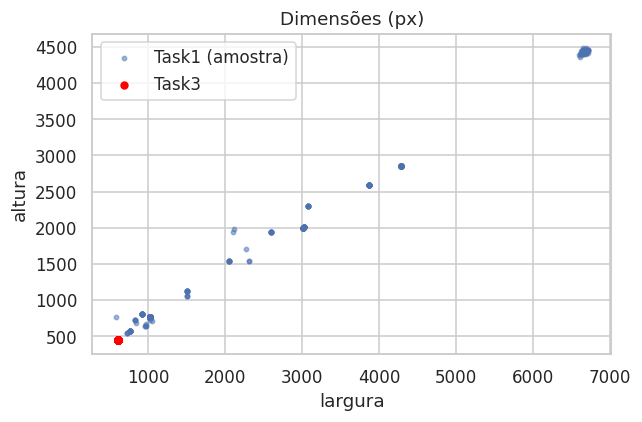

In [6]:
def dims(paths, n=None):
    if n and len(paths) > n: paths = random.sample(paths, n)
    out = []
    for p in paths:
        with Image.open(p) as im: out.append((p.stem, *im.size, im.mode))
    return pd.DataFrame(out, columns=["id", "w", "h", "mode"])

t0 = time.time()
d3 = dims(t3_img); d1 = dims(t1_img, 400)
print(f"tempo: {time.time()-t0:.1f}s")
for nome, d in [("Task3", d3), ("Task1 (amostra)", d1)]:
    print(f"\n{nome}: {len(d)} imagens | modos: {d['mode'].unique()}")
    print(" resoluções mais comuns:"); print((d["w"].astype(str) + "x" + d["h"].astype(str)).value_counts().head(6))
    print(f" largura min/max: {d.w.min()}/{d.w.max()} | altura min/max: {d.h.min()}/{d.h.max()}")
EVID["task3_resolutions"] = (d3["w"].astype(str) + "x" + d3["h"].astype(str)).value_counts().head(3).to_dict()
EVID["task1_res_range"] = [int(d1.w.min()), int(d1.w.max()), int(d1.h.min()), int(d1.h.max())]

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(d1.w, d1.h, s=8, alpha=.5, label="Task1 (amostra)"); ax.scatter(d3.w, d3.h, s=20, c="red", label="Task3")
ax.set(xlabel="largura", ylabel="altura", title="Dimensões (px)"); ax.legend(); plt.tight_layout(); plt.savefig(FIG / "03_dimensoes.png"); plt.show()

## 4. Amostras visuais

4 imagens por classe (Task 3) e 6 pares imagem/máscara (Task 1). Servem para o slide de amostras e para começar a **galeria de artefatos** (pelos, régua, bolhas, vinheta, marcação a caneta).

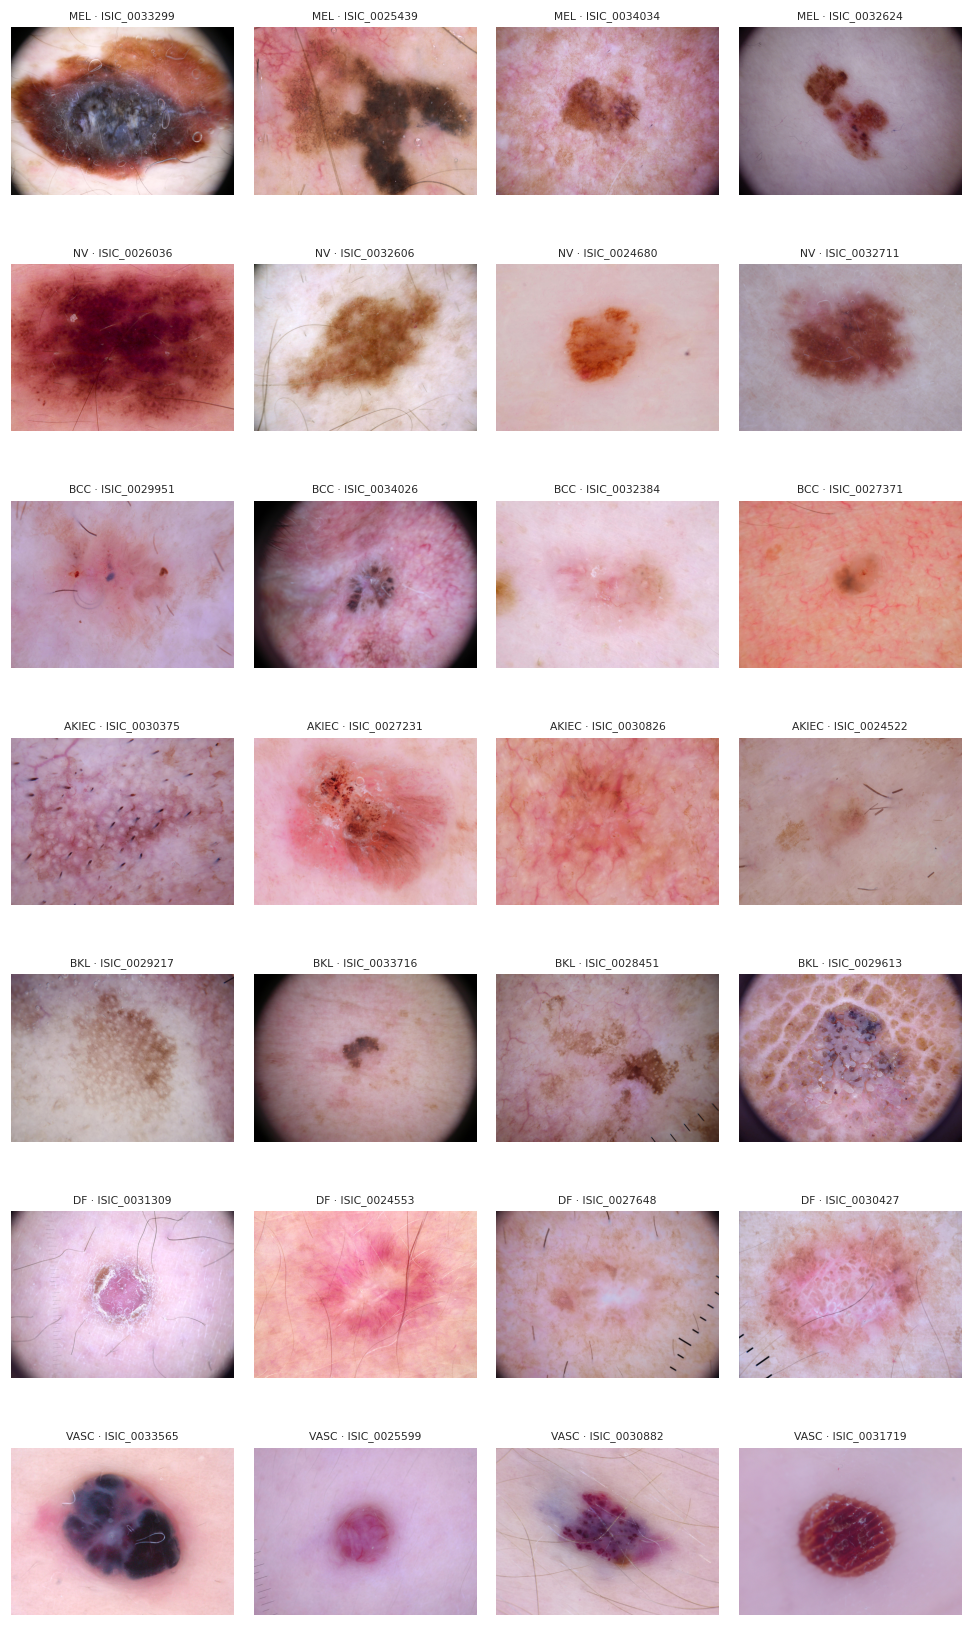

In [7]:
fig, axes = plt.subplots(len(CLASSES), 4, figsize=(9, 2.2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    ids = df.loc[df.dx == c, "image"].sample(4, random_state=SEED)
    for j, iid in enumerate(ids):
        axes[i, j].imshow(Image.open(P["task3_images"] / f"{iid}.jpg")); axes[i, j].axis("off")
        axes[i, j].set_title(f"{c} · {iid}", fontsize=7)
plt.tight_layout(); plt.savefig(FIG / "04_amostras_classes.png"); plt.show()

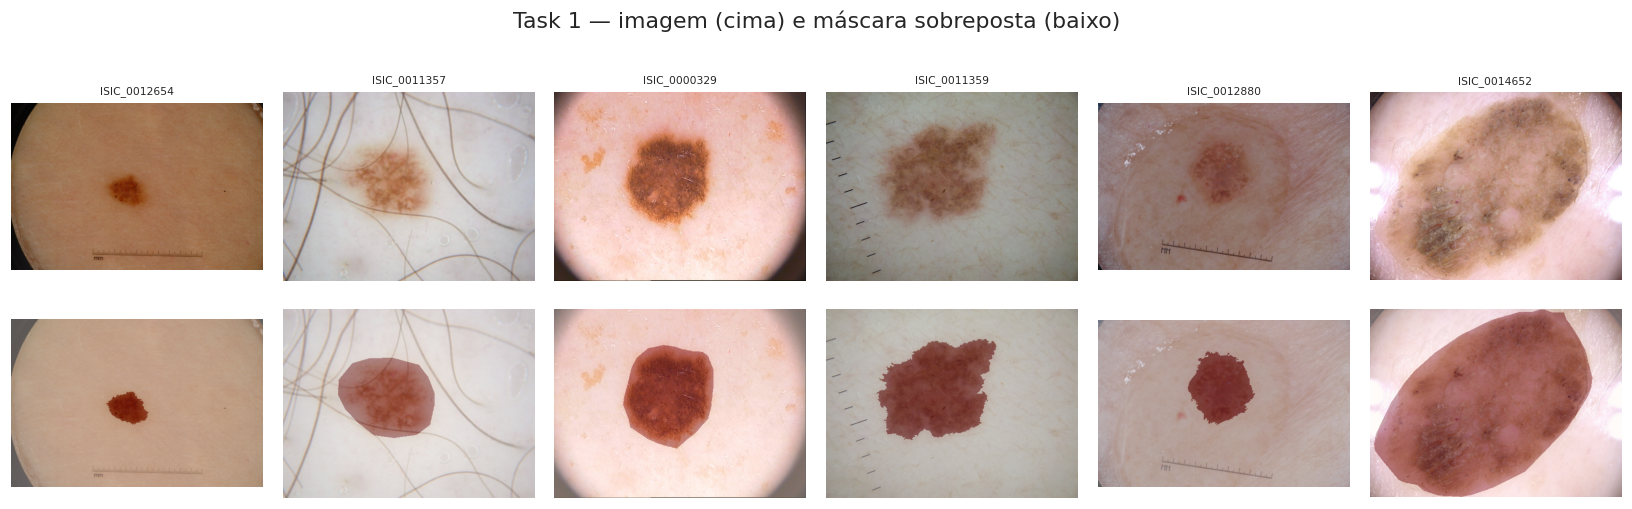

In [8]:
sel = random.sample(t1_img, 6)
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, p in enumerate(sel):
    im = Image.open(p).convert("RGB"); m = Image.open(P["task1_masks"] / f"{p.stem}_segmentation.png").convert("L")
    im.thumbnail((512, 512)); m = m.resize(im.size)
    axes[0, j].imshow(im); axes[0, j].axis("off"); axes[0, j].set_title(p.stem, fontsize=7)
    axes[1, j].imshow(im); axes[1, j].imshow(np.array(m) > 127, alpha=.35, cmap="Reds"); axes[1, j].axis("off")
plt.suptitle("Task 1 — imagem (cima) e máscara sobreposta (baixo)"); plt.tight_layout(); plt.savefig(FIG / "05_amostras_segmentacao.png"); plt.show()

## 5. Máscaras: fração de área e contato com a borda

Mede, numa amostra de 400 máscaras: fração da imagem ocupada pela lesão e se a lesão toca a borda (lesão maior que o campo de visão — caso difícil para segmentação).

           count      mean       std       min       25%       50%      75%  \
area_frac  400.0  0.220378  0.230699  0.004272  0.040455  0.126534  0.33506   

                max  
area_frac  0.955536  
toca borda: 0.125 | máscaras binárias (2 valores): 1.0


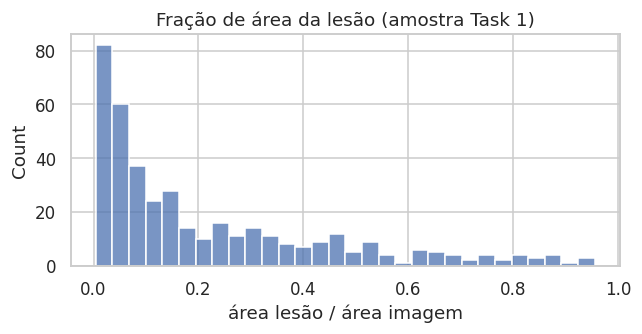

In [9]:
rows = []
for p in random.sample(t1_msk, 400):
    m = np.array(Image.open(p).convert("L").resize((256, 256))) > 127
    borda = m[0].any() or m[-1].any() or m[:, 0].any() or m[:, -1].any()
    rows.append((p.stem, m.mean(), bool(borda), np.unique(np.array(Image.open(p))).size))
mk = pd.DataFrame(rows, columns=["id", "area_frac", "toca_borda", "n_valores"])
print(mk[["area_frac"]].describe().T)
print("toca borda:", mk.toca_borda.mean().round(3), "| máscaras binárias (2 valores):", (mk.n_valores <= 2).mean())
EVID.update(mask_area_median=float(mk.area_frac.median()), mask_touch_border=float(mk.toca_borda.mean()))
fig, ax = plt.subplots(figsize=(6, 3.2)); sns.histplot(mk.area_frac, bins=30, ax=ax); ax.set(title="Fração de área da lesão (amostra Task 1)", xlabel="área lesão / área imagem")
plt.tight_layout(); plt.savefig(FIG / "06_area_mascaras.png"); plt.show()

## 6. Proxy de artefato de aquisição: vinheta (cantos escuros)

Muitas imagens dermatoscópicas têm cantos pretos (campo circular). Proxy simples: média de luminância nos 4 cantos (5% da imagem) abaixo de 40/255. É uma **medição grosseira** — pelos, régua e marcações precisam de inspeção visual (galeria) ou detector dedicado.

In [10]:
def vinheta(p, f=0.05):
    im = np.array(Image.open(p).convert("L").resize((256, 256)), dtype=float); k = int(256 * f)
    cantos = [im[:k, :k], im[:k, -k:], im[-k:, :k], im[-k:, -k:]]
    return np.mean([c.mean() for c in cantos])
amostra = df.sample(1000, random_state=SEED)
amostra = amostra.assign(canto=[vinheta(P["task3_images"] / f"{i}.jpg") for i in amostra.image])
amostra["vinheta"] = amostra.canto < 40
print("proporção com vinheta (amostra 1000):", amostra.vinheta.mean().round(3))
print(amostra.groupby("dx").vinheta.mean().reindex(CLASSES).round(3))
EVID["vignette_rate"] = float(amostra.vinheta.mean()); EVID["vignette_by_class"] = amostra.groupby("dx").vinheta.mean().reindex(CLASSES).round(3).to_dict()

proporção com vinheta (amostra 1000): 0.049
dx
MEL      0.149
NV       0.031
BCC      0.000
AKIEC    0.036
BKL      0.086
DF       0.000
VASC     0.000
Name: vinheta, dtype: float64


## 7. Hipótese de divisão treino/validação/teste

**Regra:** agrupar por `lesion_id` (nenhuma lesão em dois splits) e estratificar por classe. Proporção 70/15/15, seed fixa. O split é salvo em `data/splits/split_v1.csv` e é o **único** usado por todos os experimentos.

Para a Task 1 (segmentação), o split é por `image_id` com a mesma seed; imagens que também existem na Task 3 herdam o split da Task 3 (verificado na célula 1).

Além disso, o **teste oficial do desafio** (1.512 imagens com rótulo) fica reservado como avaliação externa — nunca usado em treino, validação ou escolha de hiperparâmetros.

In [11]:
from sklearn.model_selection import StratifiedGroupKFold

les = df.drop_duplicates("lesion_id")[["lesion_id", "dx"]]
# 1ª partição: 70% treino vs 30% resto; 2ª: resto dividido ao meio (val/test)
sgk = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
folds = np.zeros(len(df), dtype=int)
for k, (_, idx) in enumerate(sgk.split(df, df.dx, groups=df.lesion_id)): folds[idx] = k
df["fold"] = folds
# folds 0-6 → train (70%); fold 7 + metade dos grupos do fold 8 → val (~15%); restante → test (~15%)
df["split"] = np.select([df.fold < 7, df.fold == 7], ["train", "val"], "test")
g8 = df.loc[df.fold == 8, "lesion_id"].drop_duplicates().sample(frac=0.5, random_state=SEED)
df.loc[df.lesion_id.isin(g8), "split"] = "val"

res = pd.crosstab(df.dx, df.split).reindex(CLASSES)[["train", "val", "test"]]
pct = (pd.crosstab(df.dx, df.split, normalize="columns").reindex(CLASSES)[["train", "val", "test"]] * 100).round(1).add_prefix("%")
display(pd.concat([res, pct], axis=1))
print("proporção:", (df.split.value_counts(normalize=True) * 100).round(1).to_dict())
# checagem de vazamento
vaz = df.groupby("lesion_id").split.nunique()
print("lesões em mais de um split:", int((vaz > 1).sum()))
assert (vaz == 1).all()

# Task 1
t1 = pd.DataFrame({"image": [p.stem for p in t1_img]})
t1 = t1.merge(df[["image", "split"]], on="image", how="left")
rng = np.random.default_rng(SEED)
faltam = t1.split.isna()
t1.loc[faltam, "split"] = rng.choice(["train", "val", "test"], p=[.7, .15, .15], size=faltam.sum())
print("Task1 split:", t1.split.value_counts().to_dict())

out = pd.concat([df[["image", "lesion_id", "dx", "split"]].assign(task="cls"), t1.assign(task="seg", lesion_id=np.nan, dx=np.nan)])
out.to_csv(ROOT / "data/splits/split_v1.csv", index=False)
EVID["split_counts"] = df.split.value_counts().to_dict()
print("salvo em data/splits/split_v1.csv")

split,train,val,test,%train,%val,%test
dx,,,,,,
MEL,776,166,171,11.1,11.2,11.3
NV,4671,1002,1032,66.6,67.4,68.3
BCC,387,62,65,5.5,4.2,4.3
AKIEC,245,48,34,3.5,3.2,2.3
BKL,764,172,163,10.9,11.6,10.8
DF,73,19,23,1.0,1.3,1.5
VASC,101,18,23,1.4,1.2,1.5


proporção: {'train': 70.1, 'test': 15.1, 'val': 14.8}
lesões em mais de um split: 0
Task1 split: {'train': 1811, 'test': 399, 'val': 384}
salvo em data/splits/split_v1.csv


## 8. Resumo de evidências

Salvo em `reports/m1_proposta/evidencias.json` — é a fonte dos números usados nos slides da M1.

In [12]:
out = ROOT / "reports/m1_proposta/evidencias.json"; out.parent.mkdir(parents=True, exist_ok=True)
json.dump(EVID, open(out, "w"), indent=2, ensure_ascii=False, default=str)
print(json.dumps(EVID, indent=2, ensure_ascii=False, default=str))

{
  "n_task3_test": 1512,
  "n_task1": 2594,
  "n_task1_masks": 2594,
  "n_task3": 10015,
  "task1_task3_overlap": 0,
  "has_demographics": true,
  "class_counts": {
    "MEL": 1113,
    "NV": 6705,
    "BCC": 514,
    "AKIEC": 327,
    "BKL": 1099,
    "DF": 115,
    "VASC": 142
  },
  "imbalance_ratio": 58.30434782608695,
  "test_class_counts": {
    "MEL": 171,
    "NV": 909,
    "BCC": 93,
    "AKIEC": 43,
    "BKL": 217,
    "DF": 44,
    "VASC": 35
  },
  "n_lesions": 7470,
  "lesions_multi_image": 1956,
  "dx_type": {
    "histopathology": 5340,
    "serial imaging showing no change": 3704,
    "single image expert consensus": 902,
    "confocal microscopy with consensus dermoscopy": 69
  },
  "histo_share_total": 0.5332001997004493,
  "histo_share_by_class": {
    "MEL": 100.0,
    "NV": 37.3,
    "BCC": 100.0,
    "AKIEC": 100.0,
    "BKL": 69.7,
    "DF": 47.8,
    "VASC": 47.2
  },
  "task3_resolutions": {
    "600x450": 10015
  },
  "task1_res_range": [
    576,
    6708,
 